In [71]:
import numpy as np
import matplotlib.pyplot as plt

In [72]:
def euler_method(f, t0, Y0, t_end, h):
  """
  Solves the system of ODEs dY/dt = f(t, Y) using the Euler method.

  Parameters:
    f: function
      The function defining the system of ODEs.
    t0: float
      Initial time.
    Y0: ndarray
      Initial condition.
    t_end: float
      End time.
    h: float
      Step size.
  Returns:
    t_vals: ndarray
      Time points.
    Y_vals: ndarray
      Approximated solution values at each time step.
  """
  t_vals = np.arange(t0, t_end+h, h)
  Y_vals = np.zeros((len(t_vals), len(Y0)))
  Y_vals[0] = Y0
  for i in range(1, len(t_vals)):
    Y_vals[i] = Y_vals[i-1] + h*f(t_vals[i-1], Y_vals[i-1])
  return t_vals, Y_vals

In [73]:
# Example 1: System with 2 equations
def system1(t, Y):
  """Defines the system dY/dt = f(t, Y) for a two-equation system."""
  dydt = np.array([
      0*Y[0] + 1*Y[1],    # dy1/dt = y1+4y2
      -2*Y[0] + 3*Y[1]       # dy2/dt = y1+y2 (IVP)
  ])
  return dydt

In [74]:
t0, Y0, t_end, h = 0, np.array([-1, 0]), 2, 0.1
t_vals, Y_vals = euler_method(system1, t0, Y0, t_end, h)

In [75]:
# Exact solution for comparison
def exact_solution1(t):
  # return np.array([np.cos(t), -np.sin(t)])
  # return np.array([2*np.exp(3*t) + (np.exp(t) - np.exp(-t))/2, -np.exp(-t)/8 - np.exp(t)/4 + (11/8)*np.exp(3*t)])
  return np.array([np.exp(2*t) - 2*np.exp(t), 2*np.exp(2*t) - 2*np.exp(t)])

In [76]:
exact_vals = np.array([exact_solution1(t) for t in t_vals])
errors = np.abs(Y_vals - exact_vals)

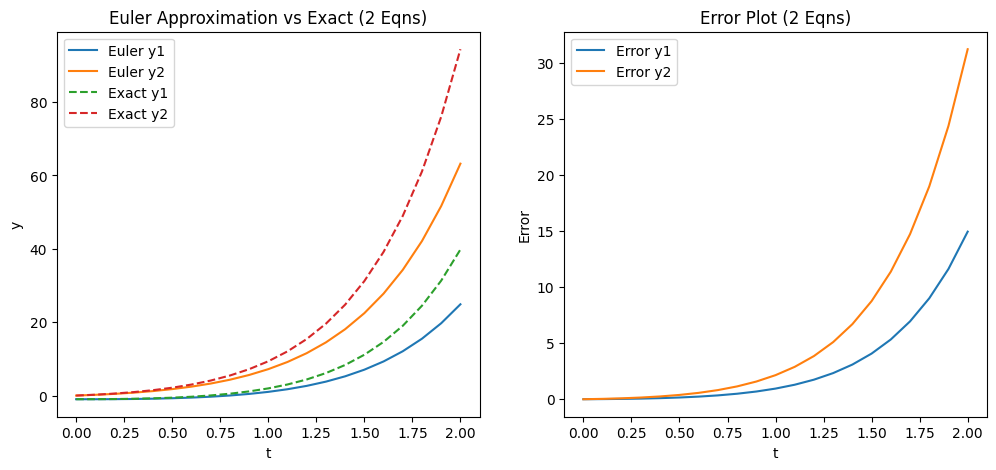

In [77]:
# Plot results
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(t_vals, Y_vals[:, 0], label='Euler y1')
plt.plot(t_vals, Y_vals[:, 1], label='Euler y2')
plt.plot(t_vals, exact_vals[:, 0], '--', label='Exact y1')
plt.plot(t_vals, exact_vals[:, 1], '--', label='Exact y2')
plt.xlabel('t')
plt.ylabel('y')
plt.legend()
plt.title('Euler Approximation vs Exact (2 Eqns)')
plt.subplot(1, 2, 2)
plt.plot(t_vals, errors[:, 0], label='Error y1')
plt.plot(t_vals, errors[:, 1], label='Error y2')
plt.xlabel('t')
plt.ylabel('Error')
plt.legend()
plt.title('Error Plot (2 Eqns)')
plt.show()

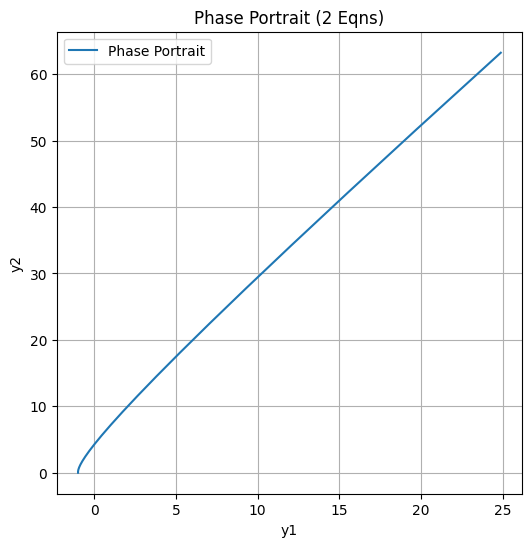

In [78]:
# Phase Portrait for the 2-equation system
plt.figure(figsize=(6, 6))
plt.plot(Y_vals[:, 0], Y_vals[:, 1], label='Phase Portrait')
plt.xlabel('y1')
plt.ylabel('y2')
plt.legend()
plt.title('Phase Portrait (2 Eqns)')
plt.grid()
plt.show()

In [79]:
# Example 2: System with 3 equations
def system2(t, Y):
  """Defines the system dY/dt = f(t, Y) for a three-equation system."""
  dydt = np.array([
      Y[1],            # dy1/dt = y2
      Y[2],            # dy2/dt = y3
      # -Y[0] - Y[1],    # dy3/dt = -y1-y2 (example dynamics)
      t**2*Y[0] - 4*Y[1] + 2*t*Y[2]+1    # dy3/dt (example dynamics)
  ])
  return dydt

In [80]:
t0, Y0, t_end, h = 0, np.array([1, 2, 3]), 5, 0.2
t_vals, Y_vals = euler_method(system2, t0, Y0, t_end, h)

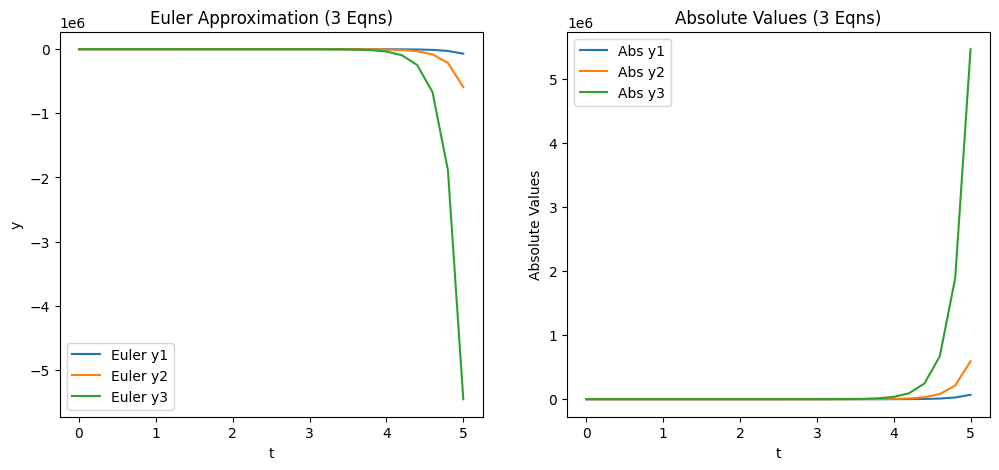

In [81]:
# Plot results
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(t_vals, Y_vals[:, 0], label='Euler y1')
plt.plot(t_vals, Y_vals[:, 1], label='Euler y2')
plt.plot(t_vals, Y_vals[:, 2], label='Euler y3')
plt.xlabel('t')
plt.ylabel('y')
plt.legend()
plt.title('Euler Approximation (3 Eqns)')
plt.subplot(1, 2, 2)
plt.plot(t_vals, np.abs(Y_vals[:, 0]), label='Abs y1')
plt.plot(t_vals, np.abs(Y_vals[:, 1]), label='Abs y2')
plt.plot(t_vals, np.abs(Y_vals[:, 2]), label='Abs y3')
plt.xlabel('t')
plt.ylabel('Absolute Values')
plt.legend()
plt.title('Absolute Values (3 Eqns)')
plt.show()